In [1]:
import pandas as pd

df = pd.read_csv("retail_data.csv")

print("Shape:", df.shape)
print("\nColumn Info:")
print(df.info())

print("\nFirst 5 rows:")
print(df.head())


Shape: (100, 9)

Column Info:
<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   InvoiceNo    100 non-null    int64  
 1   StockCode    100 non-null    str    
 2   Description  100 non-null    str    
 3   Quantity     100 non-null    int64  
 4   InvoiceDate  100 non-null    str    
 5   UnitPrice    100 non-null    float64
 6   CustomerID   100 non-null    str    
 7   Country      100 non-null    str    
 8   TotalPrice   100 non-null    float64
dtypes: float64(2), int64(2), str(5)
memory usage: 7.2 KB
None

First 5 rows:
   InvoiceNo StockCode      Description  Quantity InvoiceDate  UnitPrice  \
0      10000      P754      Left Candle        12   8/20/2024       3.48   
1      10001      P214     Radio Candle         6   9/15/2024      49.96   
2      10002      P125         Once Mug        18  12/18/2024      41.97   
3      10003      P859  Positive B

In [2]:
import pandas as pd

# Load the uploaded CSV
df = pd.read_csv("retail_data.csv")

# Basic structure
print("Shape:", df.shape)
print("\nColumn Info:")
print(df.info())

# Preview
print("\nFirst 5 rows:")
print(df.head())


Shape: (100, 9)

Column Info:
<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   InvoiceNo    100 non-null    int64  
 1   StockCode    100 non-null    str    
 2   Description  100 non-null    str    
 3   Quantity     100 non-null    int64  
 4   InvoiceDate  100 non-null    str    
 5   UnitPrice    100 non-null    float64
 6   CustomerID   100 non-null    str    
 7   Country      100 non-null    str    
 8   TotalPrice   100 non-null    float64
dtypes: float64(2), int64(2), str(5)
memory usage: 7.2 KB
None

First 5 rows:
   InvoiceNo StockCode      Description  Quantity InvoiceDate  UnitPrice  \
0      10000      P754      Left Candle        12   8/20/2024       3.48   
1      10001      P214     Radio Candle         6   9/15/2024      49.96   
2      10002      P125         Once Mug        18  12/18/2024      41.97   
3      10003      P859  Positive B

In [3]:
# 1. Convert InvoiceDate to datetime
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

# 2. Check for missing values
print("Missing values:\n", df.isnull().sum())

# 3. Check for duplicates
print("\nDuplicate rows:", df.duplicated().sum())

# 4. Check for invalid Quantity and UnitPrice
print("\nNegative Quantities:\n", df[df['Quantity'] < 0])
print("\nNegative Prices:\n", df[df['UnitPrice'] < 0])


Missing values:
 InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
TotalPrice     0
dtype: int64

Duplicate rows: 0

Negative Quantities:
 Empty DataFrame
Columns: [InvoiceNo, StockCode, Description, Quantity, InvoiceDate, UnitPrice, CustomerID, Country, TotalPrice]
Index: []

Negative Prices:
 Empty DataFrame
Columns: [InvoiceNo, StockCode, Description, Quantity, InvoiceDate, UnitPrice, CustomerID, Country, TotalPrice]
Index: []


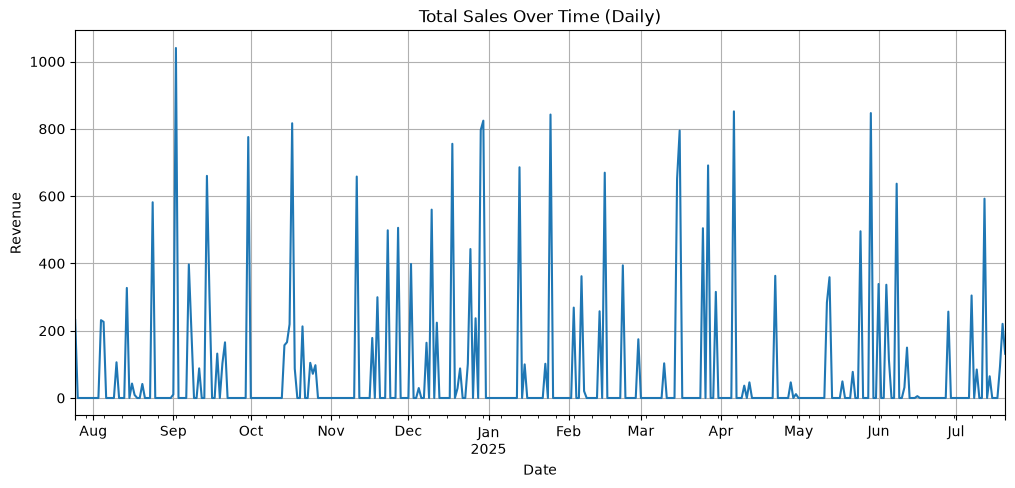

C:\Users\shour\AppData\Local\Temp\ipykernel_19380\86558467.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_products.values, y=top_products.index, palette="viridis")


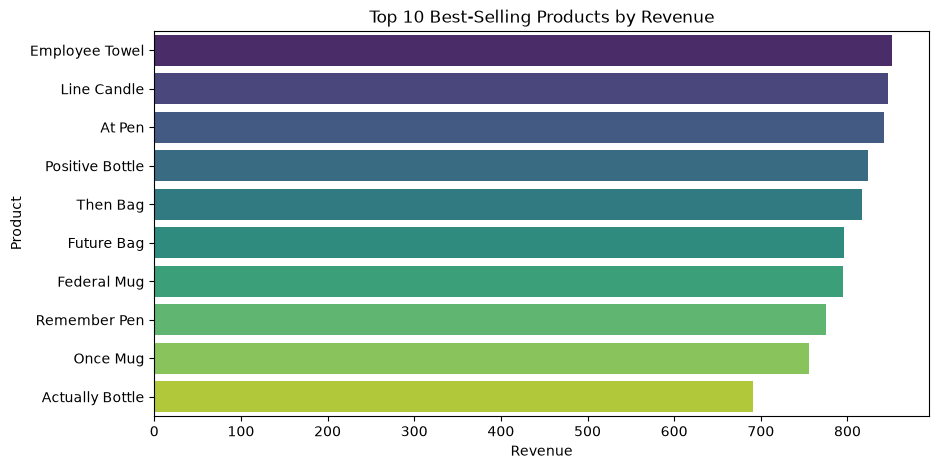

C:\Users\shour\AppData\Local\Temp\ipykernel_19380\86558467.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=country_sales.values, y=country_sales.index, palette="mako")


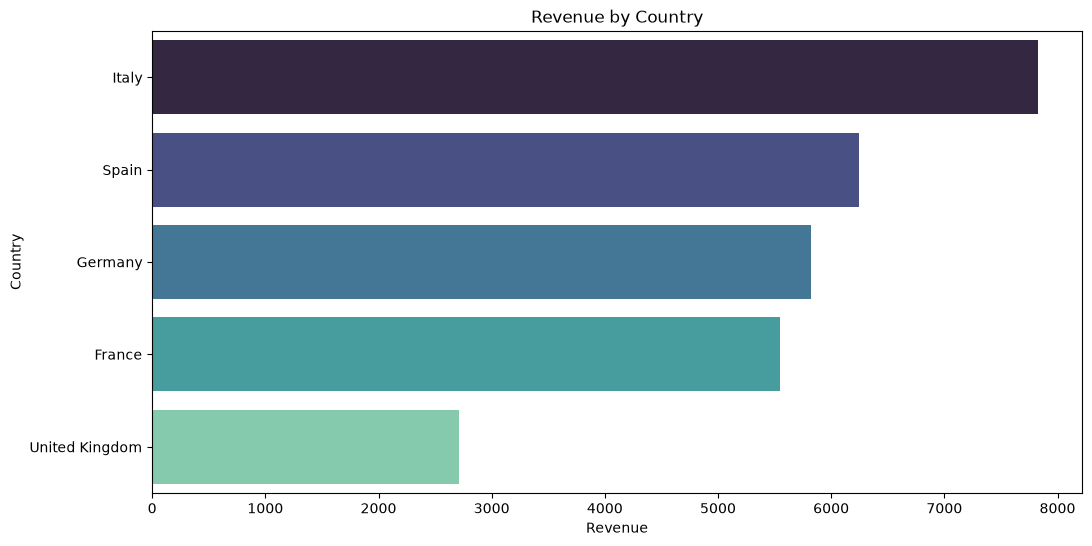

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure datetime is the index for time-series plots
df.set_index('InvoiceDate', inplace=True)

# 1. Daily Sales Over Time
daily_sales = df.resample('D').sum(numeric_only=True)['TotalPrice']
plt.figure(figsize=(12, 5))
daily_sales.plot()
plt.title("Total Sales Over Time (Daily)")
plt.xlabel("Date")
plt.ylabel("Revenue")
plt.grid(True)
plt.show()

# 2. Top 10 Products by Revenue
top_products = df.groupby('Description')['TotalPrice'].sum().sort_values(ascending=False).head(10)
plt.figure(figsize=(10, 5))
sns.barplot(x=top_products.values, y=top_products.index, palette="viridis")
plt.title("Top 10 Best-Selling Products by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Product")
plt.show()

# 3. Sales by Country
country_sales = df.groupby('Country')['TotalPrice'].sum().sort_values(ascending=False)
plt.figure(figsize=(12, 6))
sns.barplot(x=country_sales.values, y=country_sales.index, palette="mako")
plt.title("Revenue by Country")
plt.xlabel("Revenue")
plt.ylabel("Country")
plt.show()


In [ ]:
# Reset index to work with InvoiceDate as a column again
df = df.reset_index()

# 1. Total spend per customer
total_spend = df.groupby('CustomerID')['TotalPrice'].sum().rename("TotalSpend")

# 2. Purchase frequency (unique invoices)
purchase_freq = df.groupby('CustomerID')['InvoiceNo'].nunique().rename("PurchaseFrequency")

# 3. Average basket size (quantity per invoice)
avg_basket = df.groupby('CustomerID')['Quantity'].mean().rename("AvgBasketSize")

# 4. Average spend per basket (optional)
avg_spend = (df.groupby('CustomerID')['TotalPrice'].sum() / df.groupby('CustomerID')['InvoiceNo'].nunique()).rename("AvgSpendPerBasket")

# Combine all features
customer_df = pd.concat([total_spend, purchase_freq, avg_basket, avg_spend], axis=1).reset_index()

# Preview
customer_df.head()


,CustomerID,TotalSpend,PurchaseFrequency,AvgBasketSize,AvgSpendPerBasket
0,C1000,41.76,1,12.000000,41.760000
1,C1001,1123.02,3,11.666667,374.340000
2,C1002,1195.61,6,8.000000,199.268333
3,C1004,921.33,2,18.500000,460.665000
4,C1006,1858.99,3,15.333333,619.663333


from matplotlib import pyplot as plt
_df_0['TotalSpend'].plot(kind='hist', bins=20, title='TotalSpend')
plt.gca().spines[['top', 'right',]].set_visible(False)

from matplotlib import pyplot as plt
_df_1['PurchaseFrequency'].plot(kind='hist', bins=20, title='PurchaseFrequency')
plt.gca().spines[['top', 'right',]].set_visible(False)

from matplotlib import pyplot as plt
_df_2['AvgBasketSize'].plot(kind='hist', bins=20, title='AvgBasketSize')
plt.gca().spines[['top', 'right',]].set_visible(False)

from matplotlib import pyplot as plt
_df_3['AvgSpendPerBasket'].plot(kind='hist', bins=20, title='AvgSpendPerBasket')
plt.gca().spines[['top', 'right',]].set_visible(False)

from matplotlib import pyplot as plt
import seaborn as sns
_df_4.groupby('CustomerID').size().plot(kind='barh', color=sns.palettes.mpl_palette('Dark2'))
plt.gca().spines[['top', 'right',]].set_visible(False)

... (11 outputs left out)

<string>:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.



from matplotlib import pyplot as plt
import seaborn as sns
figsize = (12, 1.2 * len(_df_14['CustomerID'].unique()))
plt.figure(figsize=figsize)
sns.violinplot(_df_14, x='AvgBasketSize', y='CustomerID', inner='stick', palette='Dark2')
sns.despine(top=True, right=True, bottom=True, left=True)

<string>:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.



from matplotlib import pyplot as plt
import seaborn as sns
figsize = (12, 1.2 * len(_df_15['CustomerID'].unique()))
plt.figure(figsize=figsize)
sns.violinplot(_df_15, x='AvgSpendPerBasket', y='CustomerID', inner='stick', palette='Dark2')
sns.despine(top=True, right=True, bottom=True, left=True)

In [ ]:
# Define High Value Customers (1 = high value, 0 = low value)
median_spend = customer_df['TotalSpend'].median()
customer_df['HighValue'] = (customer_df['TotalSpend'] > median_spend).astype(int)

# Drop TotalSpend from features (since it's derived from target)
features = customer_df.drop(columns=['CustomerID', 'TotalSpend', 'HighValue'])
target = customer_df['HighValue']


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import classification_report

# Split the data
X_train, X_test, y_train, y_test = train_test_split(features, target, test_size=0.3, random_state=42)

# Random Forest
rf = RandomForestClassifier(random_state=42)
rf.fit(X_train, y_train)
rf_preds = rf.predict(X_test)

# XGBoost
xgb = XGBClassifier(use_label_encoder=False, eval_metric='logloss', random_state=42)
xgb.fit(X_train, y_train)
xgb_preds = xgb.predict(X_test)

# Evaluation
print("Random Forest Performance:")
print(classification_report(y_test, rf_preds))

print("\nXGBoost Performance:")
print(classification_report(y_test, xgb_preds))


Random Forest Performance:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         6
           1       1.00      1.00      1.00         7

    accuracy                           1.00        13
   macro avg       1.00      1.00      1.00        13
weighted avg       1.00      1.00      1.00        13


XGBoost Performance:
              precision    recall  f1-score   support

           0       1.00      0.83      0.91         6
           1       0.88      1.00      0.93         7

    accuracy                           0.92        13
   macro avg       0.94      0.92      0.92        13
weighted avg       0.93      0.92      0.92        13



/usr/local/lib/python3.11/dist-packages/xgboost/training.py:183: UserWarning: [19:18:21] WARNING: /workspace/src/learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


/tmp/ipython-input-9-2260295088.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=feat_imp_df, palette="crest")


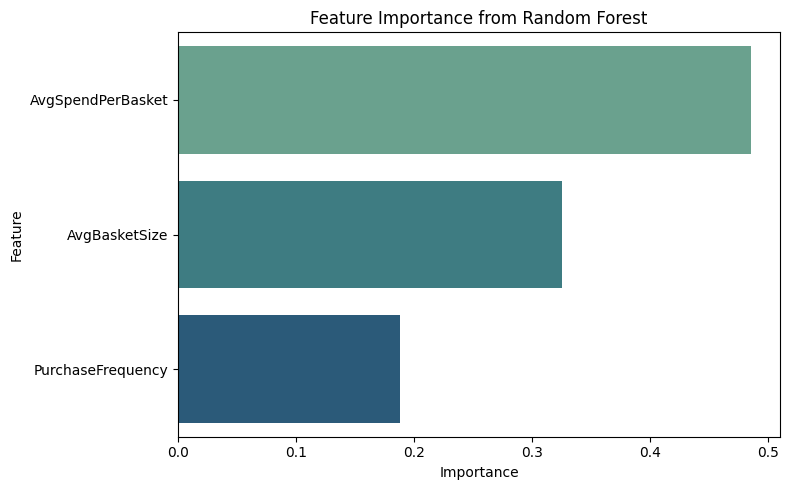

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Feature importance from Random Forest
importances = rf.feature_importances_
feature_names = features.columns
feat_imp_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances}).sort_values(by='Importance', ascending=False)

# Plot
plt.figure(figsize=(8, 5))
sns.barplot(x='Importance', y='Feature', data=feat_imp_df, palette="crest")
plt.title("Feature Importance from Random Forest")
plt.tight_layout()
plt.show()
